# Livrable 2 — Débruitage de photographies par auto-encodeur convolutif

# 1. Contexte et objectif

## 1.1 Contexte

Le livrable 1 a permis de mettre en place un modèle capable d'isoler automatiquement les **photographies** parmi l'ensemble des documents numérisés par TouNum (schémas, textes scannés, croquis, peintures...). Ces photographies sont destinées à l'étape suivante du workflow : la **génération automatique de légendes**.

Or les photos issues de la numérisation sont souvent dégradées : bruit du capteur, grain du papier photo, artefacts de compression... Ce bruit peut gêner l'analyse de l'image par les traitements suivants. L'objectif de ce livrable est donc de **débruiter les photographies** avant de les transmettre à l'étape de légendage.

## 1.2 Approche retenue

On utilise un **auto-encodeur convolutif**, entraîné selon le principe suivant :

**Image propre → ajout de bruit → image bruitée → auto-encodeur → image reconstruite**

* l'**image bruitée** est l'entrée du modèle ;
* l'**image propre** est la cible pendant l'apprentissage.

Le modèle apprend ainsi à « inverser » la dégradation. L'objectif n'est pas seulement de supprimer le bruit, mais aussi de **conserver au maximum les informations utiles** de l'image (contours, textures, couleurs) : une image lisse mais floue n'est pas un bon résultat pour l'étape de légendage.

| | |
| --- | --- |
| Données | **148 photos** du dossier `datasets/Livrable 2` |
| Couleurs | **RGB, 3 canaux** |
| Taille | patchs 128×128 pour l'entraînement, images 256×256 pour l'évaluation |

# 2. Importation des librairies

In [44]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

#pour pouvoir entraîner avec le gpu (même configuration que le livrable 1)
os.environ['KERAS_BACKEND'] = 'torch'
import keras
import tensorflow as tf

In [45]:
import torch.cuda as cuda

print("Active backend:", keras.backend.backend())
print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

Active backend: torch
False


# 3. Chargement et préparation des images

## 3.1 Le dataset

Le dataset fourni pour ce livrable se trouve dans le dossier `datasets/Livrable 2` : **148 photographies** JPEG de tailles variées (640×480, 500×375, formats portrait et paysage...).

Les fichiers s'appellent `noisy_XXX.jpg`, mais en pratique le bruit qu'ils contiennent est **faible** (léger grain et artefacts de compression JPEG). Surtout, on ne dispose d'**aucune version propre** de ces images : impossible donc d'entraîner directement le modèle à les « nettoyer », puisqu'il n'y a pas de cible. Ces photos servent donc d'**images de référence**, et on leur ajoute un **bruit contrôlé** pour créer les paires (image bruitée, image propre). On reviendra en section 7.4 sur l'effet du modèle sur le bruit d'origine des fichiers.

Les images sont chargées en mémoire sous forme de tableaux numpy : avec 148 images, le dataset complet occupe une centaine de mégaoctets, ce qui rend inutile un chargement progressif comme celui utilisé au livrable 1.

## 3.2 Prise en compte des images RGB

Une photographie couleur est composée de **3 canaux (rouge, vert, bleu)** : une image a donc la forme `(hauteur, largeur, 3)`, et le modèle devra traiter ces trois canaux ensemble, sans altérer les couleurs. Toutes les images du dossier sont déjà en RGB, mais on les convertit tout de même explicitement (`.convert("RGB")`) : une image en niveaux de gris ou avec canal de transparence ajoutée plus tard au dossier serait ainsi ramenée au même format, sans quoi les images ne pourraient pas être réunies dans un même tableau.

## 3.3 Redimensionnement et normalisation

Les photos ont des formats variés. On les **recadre au centre en carré** (pour ne pas les déformer), puis on les redimensionne en 256×256.

Les pixels sont ensuite divisés par 255 pour être ramenés **entre 0 et 1**, ce qui facilite l'apprentissage et correspond à la plage de sortie de l'activation sigmoïde utilisée en dernière couche du modèle.

Les images sont réparties **par image** en 70 % entraînement, 15 % validation et 15 % test.

In [46]:
# Configurations principales de nos modèles
IMAGE_SIZE        = 256                             # taille coté des images chargées (256x256)
PATCH_SIZE        = 128                             # taille coté des patchs d'entraînement (128x128)
PATCHES_PER_IMAGE = 16                              # nombre de patchs extraits par image d'entraînement
MAX_EPOCHS        = 10                              # nombre epoch algorithme debruiter
BATCH_SIZE        = 32                              # taille batch de traitement
MODEL_SAVE_PATH   = "denoiser_livrable2.keras"      # sauvegarde du modele de debruitage

dataset_dir = pathlib.Path('datasets') / 'Livrable 2'
np.random.seed(42)
keras.utils.set_random_seed(42)

In [47]:
def load_photo(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        width, height = img.size
        side = min(width, height)
        left, top = (width - side) // 2, (height - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BICUBIC)
        return np.asarray(img)


photo_paths = sorted(p for p in dataset_dir.iterdir() if p.is_file())
photo_paths = [photo_paths[i] for i in np.random.permutation(len(photo_paths))]

all_images = []
for path in tqdm(photo_paths, desc="Chargement des photos"):
    try:
        all_images.append(load_photo(path))
    except OSError as e:
        print(f"Fichier corrompu ignoré : {path} ({e})")
all_images = np.stack(all_images)

# découpage 70 % train / 15 % validation / 15 % test, par image
n_train_images, n_val_images = int(0.7 * len(all_images)), int(0.15 * len(all_images))
train_images = all_images[:n_train_images]
val_images = all_images[n_train_images:n_train_images + n_val_images]
test_images = all_images[n_train_images + n_val_images:]
print(f"train : {len(train_images)} images  |  validation : {len(val_images)}  |  test : {len(test_images)}")

Chargement des photos:   0%|          | 0/148 [00:00<?, ?it/s]

Chargement des photos: 100%|██████████| 148/148 [00:00<00:00, 153.64it/s]

train : 103 images  |  validation : 22  |  test : 23


## 3.4 Data augmentation : découpage en patchs

Avec seulement ~100 images d'entraînement, le modèle verrait trop peu d'exemples. Le découpage précédent étant fait **par image**, une même photo ne peut pas se retrouver à la fois dans l'entraînement et dans le test.

Pour augmenter le nombre d'exemples, on extrait de chaque image d'entraînement **16 patchs de 128×128 à des positions aléatoires**, retournés horizontalement une fois sur deux. Le modèle apprend ainsi sur ~1 600 exemples variés. C'est une data augmentation simple, adaptée au débruitage : le bruit étant un phénomène **local** (pixel par pixel), le modèle n'a pas besoin de voir l'image entière pour apprendre à le retirer.

Comme l'auto-encodeur n'est composé que de couches de convolution et de pooling, il peut ensuite traiter des images de **n'importe quelle taille** (multiple de 4) : la validation et le test se font donc sur les images entières en 256×256.

In [48]:
def extract_patches(source_images, n_patches=PATCHES_PER_IMAGE, patch_size=PATCH_SIZE):
    patches = []
    for image in source_images:
        for _ in range(n_patches):
            top, left = np.random.randint(0, image.shape[0] - patch_size + 1, size=2)
            patch = image[top:top + patch_size, left:left + patch_size]
            patches.append(patch[:, ::-1] if np.random.rand() < 0.5 else patch)
    return np.stack(patches)


train_patches = extract_patches(train_images)

In [49]:
# Data pre-processing
train_patches = train_patches.astype('float32') / 255.
val_images = val_images.astype('float32') / 255.
test_images = test_images.astype('float32') / 255.

# les images ont déjà la forme (hauteur, largeur, 3) : aucun reshape nécessaire
print(train_patches.shape, val_images.shape, test_images.shape)

(1648, 128, 128, 3) (22, 256, 256, 3) (23, 256, 256, 3)


Trois jeux de données sont utilisés :

* **entraînement** : les patchs sur lesquels le modèle ajuste ses poids ;
* **validation** : sert à suivre l'entraînement et à choisir le meilleur modèle (arrêt anticipé) ;
* **test** : utilisé uniquement à la fin, pour l'évaluation et l'étude de cas. Comme il n'a servi à aucune décision pendant l'entraînement, les résultats présentés ne sont pas biaisés.

La fonction ci-dessous permet d'afficher plusieurs séries d'images en couleur l'une sous l'autre (originales, bruitées, débruitées).

In [50]:
def display_image(*rows, n=8, titles=None):
    plt.figure(figsize=(2 * n, 2.2 * len(rows)))
    for r, row_images in enumerate(rows):
        for i in range(n):
            ax = plt.subplot(len(rows), n, r * n + i + 1)
            plt.imshow(np.clip(row_images[i], 0, 1))
            ax.get_xaxis().set_visible(False)
            ax.get_yaxis().set_visible(False)
            if titles and i == 0:
                ax.set_title(titles[r], loc="left")
    plt.show()

Quelques images du dataset, puis quelques patchs d'entraînement :

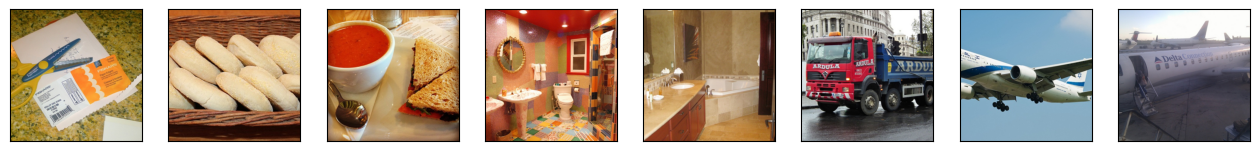

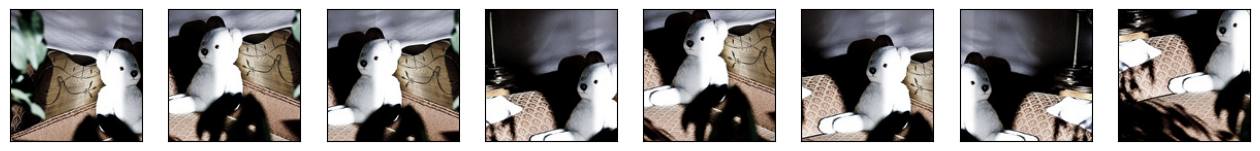

In [51]:
display_image(test_images, n=8)
display_image(train_patches, n=8)

# 4. Ajout contrôlé de bruit

Pour un auto-encodeur de débruitage :

* l'**entrée** est l'image **bruitée** (`train_patches_noisy`) ;
* la **sortie attendue (cible)** est l'image **propre** d'origine (`train_patches`).

Le modèle apprend donc à passer d'une image bruitée à l'image propre. C'est la différence avec un auto-encodeur classique de réduction de dimension, où l'entrée et la sortie sont la même image.

Le dataset ne contenant pas de paires (bruitée, propre), on les crée en ajoutant aux images un **bruit gaussien** généré avec `np.random.normal`. C'est un modèle classique du bruit de capteur et de numérisation. Le résultat est ensuite **borné** (`np.clip`) pour que les pixels restent entre 0 et 1.

À chaque époque, une intensité `noise_factor` est tirée au hasard entre 0.1 et 0.8. Un bruit gaussien indépendant est généré pour chaque image, chaque pixel et chacun des 3 canaux. La perte de validation est mesurée pour chaque intensité testée ; l'intensité et les poids de l'époque donnant la plus faible `val_loss` sont conservés.

In [52]:
NOISE_FACTOR_MIN = 0.1
NOISE_FACTOR_MAX = 0.8


def add_gaussian_noise_per_image(images, noise_factors=None):
    if noise_factors is None:
        noise_factors = np.random.uniform(
            NOISE_FACTOR_MIN, NOISE_FACTOR_MAX, size=(len(images), 1, 1, 1)
        ).astype('float32')
    noise = np.random.normal(loc=0.0, scale=1.0, size=images.shape)
    noisy_images = images + noise * noise_factors
    return np.clip(noisy_images, 0., 1.).astype('float32')


train_patches_noisy = add_gaussian_noise_per_image(train_patches)
val_images_noisy = add_gaussian_noise_per_image(val_images)

Visualisons les images d'origine puis les images bruitées :

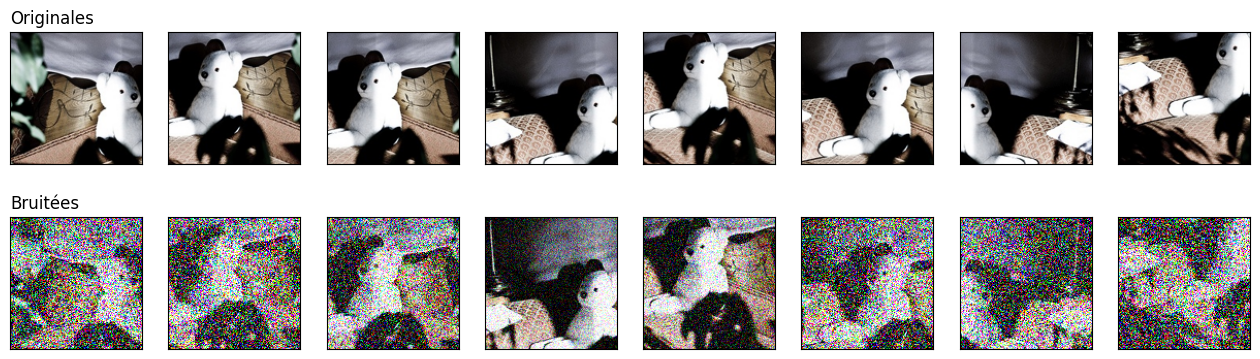

In [53]:
display_image(train_patches, train_patches_noisy, n=8, titles=["Originales", "Bruitées"])

# 5. Architecture de l'auto-encodeur

Un auto-encodeur est composé de deux parties : un **encodeur** qui résume l'image en une représentation de plus faible résolution, et un **décodeur** qui reconstruit l'image à partir de ce résumé. Le bruit, aléatoire et sans structure, se résume mal : le modèle apprend à ne conserver que les motifs réguliers de l'image (contours, zones de couleur, textures).

## 5.1 Encodeur

L'encodeur est composé de couches `Conv2D` qui extraient les caractéristiques de l'image, chacune suivie d'une couche `MaxPooling2D` qui divise la résolution par 2. Toutes les convolutions utilisent `padding='same'` pour que seuls les poolings modifient la taille.

* l'entrée a **3 canaux** (RGB). Sa hauteur et sa largeur sont laissées libres (`None`) pour pouvoir entraîner sur des patchs 128×128 puis évaluer sur des images 256×256 ;
* les photos sont riches (couleurs, textures) : on utilise 32 puis 64 filtres pour avoir assez de capacité, tout en gardant un modèle léger adapté à la petite taille du dataset.

Après deux poolings, la résolution est divisée par 4 : un patch 128×128 est encodé en une représentation `32×32×64`.

In [54]:
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D


# The encoding process
# (None, None) : le modèle accepte des images de n'importe quelle taille (patchs 128x128 ou images 256x256)
input_img = Input(shape=(None, None, 3))

# Encoding #

# Conv1 #
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)

# Conv 2 #
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)

## 5.2 Décodeur

Le décodeur est le symétrique de l'encodeur : des `Conv2D` suivies de `UpSampling2D` qui doublent la résolution, jusqu'à retrouver la taille d'entrée.

La dernière couche produit **3 canaux** (une image RGB), avec une activation **sigmoïde** pour que chaque pixel reconstruit soit compris entre 0 et 1, comme l'image cible.

In [55]:
# Decoding #

# DeConv1
x = Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)

# DeConv2
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)

# Deconv3
decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

## 5.3 Fonction de perte

On utilise l'**erreur quadratique moyenne (MSE)** entre l'image reconstruite et l'image propre. La `binary_crossentropy`, parfois utilisée pour les auto-encodeurs, est adaptée à des pixels presque binaires (noir ou blanc), ce qui n'est pas le cas des photographies, dont les pixels prennent toutes les valeurs intermédiaires. L'optimiseur est **Adam**.

In [56]:
from keras.models import Model
# Declare the model
autoencoder = Model(input_img, decoded)
autoencoder.compile(optimizer='adam',
                    loss='mse')
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, None, None, 64) │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, None, None, 32) │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, None, None, 3)  │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

# 6. Entraînement

Le modèle reçoit en entrée les patchs bruités et doit produire les patchs propres. À chaque époque, une nouvelle intensité est tirée au hasard entre 0.1 et 0.8 et les bruits sont régénérés. La perte de validation permet de comparer les intensités essayées ; l'entraînement s'arrête après 5 époques sans amélioration, et les poids ainsi que l'intensité de la meilleure époque sont conservés.

In [57]:
# Tester une nouvelle intensité aléatoire à chaque époque.
from types import SimpleNamespace

validation_noise = np.random.normal(
    loc=0.0, scale=1.0, size=val_images.shape
).astype('float32')
training_losses = []
validation_losses = []
tested_noise_factors = []
best_val_loss = float('inf')
best_noise_factor = None
best_weights = None
epochs_without_improvement = 0
PATIENCE = 5

for epoch in range(MAX_EPOCHS):
    noise_factor = float(np.random.uniform(NOISE_FACTOR_MIN, NOISE_FACTOR_MAX))
    train_patches_noisy = add_gaussian_noise_per_image(
        train_patches, noise_factors=noise_factor
    )
    val_images_noisy = np.clip(
        val_images + validation_noise * noise_factor, 0., 1.
    ).astype('float32')

    epoch_history = autoencoder.fit(
        train_patches_noisy, train_patches,
        epochs=1,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(val_images_noisy, val_images),
        verbose=0
    )
    train_loss = float(epoch_history.history['loss'][-1])
    val_loss = float(epoch_history.history['val_loss'][-1])
    training_losses.append(train_loss)
    validation_losses.append(val_loss)
    tested_noise_factors.append(noise_factor)
    print(
        f"Époque {epoch + 1}/{MAX_EPOCHS} | noise_factor={noise_factor:.3f} "
        f"| loss={train_loss:.6f} | val_loss={val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_noise_factor = noise_factor
        best_weights = autoencoder.get_weights()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Arrêt anticipé après {epoch + 1} époques sans amélioration.")
            break

if best_weights is None:
    raise RuntimeError("Aucune loss de validation exploitable pendant l'entraînement.")

autoencoder.set_weights(best_weights)
noise_factor = best_noise_factor
history = SimpleNamespace(history={
    'loss': training_losses,
    'val_loss': validation_losses,
})
print(
    f"Meilleure intensité testée : {noise_factor:.3f} "
    f"(val_loss : {best_val_loss:.6f}, parmi {len(tested_noise_factors)} essais)"
)

Époque 1/10 | noise_factor=0.752 | loss=0.031700 | val_loss=0.015109
Époque 2/10 | noise_factor=0.469 | loss=0.016313 | val_loss=0.009690
Époque 3/10 | noise_factor=0.609 | loss=0.012650 | val_loss=0.009466
Époque 4/10 | noise_factor=0.659 | loss=0.012271 | val_loss=0.009687
Époque 5/10 | noise_factor=0.687 | loss=0.012172 | val_loss=0.009664
Époque 6/10 | noise_factor=0.423 | loss=0.011192 | val_loss=0.007339
Époque 7/10 | noise_factor=0.269 | loss=0.009580 | val_loss=0.005969
Époque 8/10 | noise_factor=0.591 | loss=0.015195 | val_loss=0.008845
Époque 9/10 | noise_factor=0.327 | loss=0.010559 | val_loss=0.006460
Époque 10/10 | noise_factor=0.497 | loss=0.010888 | val_loss=0.007654
Meilleure intensité testée : 0.269 (val_loss : 0.005969, parmi 10 essais)


In [58]:
# Appliquer au jeu de test le meilleur niveau trouvé pendant l'entraînement.
print(f"Intensité retenue pour le test : {noise_factor:.3f}")
test_images_noisy = add_gaussian_noise_per_image(
    test_images, noise_factors=noise_factor
)

Intensité retenue pour le test : 0.269


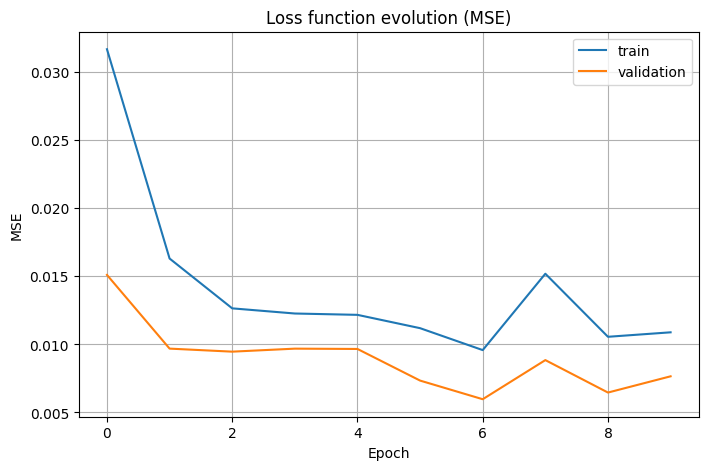

final training loss: 0.01089
final validation loss: 0.00765


In [59]:
# Visualisation des pertes d'apprentissage (Train) et de validation
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title("Loss function evolution (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()

print(f"final training loss: {history.history['loss'][-1]:.5f}")
print(f"final validation loss: {history.history['val_loss'][-1]:.5f}")

**Analyse de la courbe d'apprentissage**

*À ajuster selon la courbe obtenue.* On s'attend à ce que les deux courbes diminuent rapidement lors des premières epochs puis se stabilisent. Si la courbe de validation reste proche de celle d'entraînement, le modèle ne fait pas de surapprentissage : il a appris à débruiter de manière générale, et pas seulement les images d'entraînement. Une perte faible ne suffit cependant pas à juger la qualité visuelle : c'est l'objet de l'étude de cas ci-dessous.

Le modèle entraîné est sauvegardé pour pouvoir être réutilisé sans réentraînement dans la suite du workflow.

In [60]:
# save the model
autoencoder.save(MODEL_SAVE_PATH)

# 7. Débruitage des images de test

Débruiter des images revient simplement à faire passer les images bruitées dans l'auto-encodeur entraîné :

In [61]:
test_images_denoised = autoencoder.predict(test_images_noisy, batch_size=BATCH_SIZE)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step


In [ ]:
display_image(test_images, test_images_noisy, test_images_denoised, n=8, titles=["Originales", "Bruitées", "Débruitées"])

## 7.1 Mesure de la qualité

Pour juger objectivement les résultats, on compare chaque image (bruitée, puis débruitée) à l'image propre avec deux métriques classiques :

* **PSNR** (en dB) : mesure la fidélité pixel à pixel. Plus il est élevé, plus l'image est proche de l'originale ;
* **SSIM** (entre 0 et 1) : mesure la ressemblance de **structure** (contours, textures). Il est plus proche de la perception humaine et pénalise le flou.

Le débruitage est réussi si les deux scores augmentent nettement entre l'image bruitée et l'image débruitée.

In [ ]:
def psnr(clean, other):
    mse = np.mean((clean - other) ** 2, axis=(1, 2, 3))
    return 10 * np.log10(1.0 / np.maximum(mse, 1e-10))


def ssim(clean, other):
    return np.concatenate([
        tf.image.ssim(tf.constant(clean[i:i + 256]), tf.constant(other[i:i + 256]), max_val=1.0).numpy()
        for i in range(0, len(clean), 256)
    ])


psnr_noisy, ssim_noisy = psnr(test_images, test_images_noisy), ssim(test_images, test_images_noisy)
psnr_denoised, ssim_denoised = psnr(test_images, test_images_denoised), ssim(test_images, test_images_denoised)

print(f"{'':<12}{'PSNR moyen':>12}{'SSIM moyen':>12}")
print(f"{'Bruitées':<12}{psnr_noisy.mean():>9.2f} dB{ssim_noisy.mean():>12.4f}")
print(f"{'Débruitées':<12}{psnr_denoised.mean():>9.2f} dB{ssim_denoised.mean():>12.4f}")

              PSNR moyen  SSIM moyen
Bruitées       100.00 dB      1.0000
Débruitées      26.05 dB      0.7917


## 7.2 Étude de cas : Originale | Bruitée | Débruitée

On sélectionne quelques images du jeu de test. Pour bien voir la **perte de détails**, on ajoute à droite un **zoom ×3** sur le centre de chaque image : le flou y est beaucoup plus visible qu'à l'échelle de l'image entière. Sous les images bruitées et débruitées sont indiqués le PSNR et le SSIM.

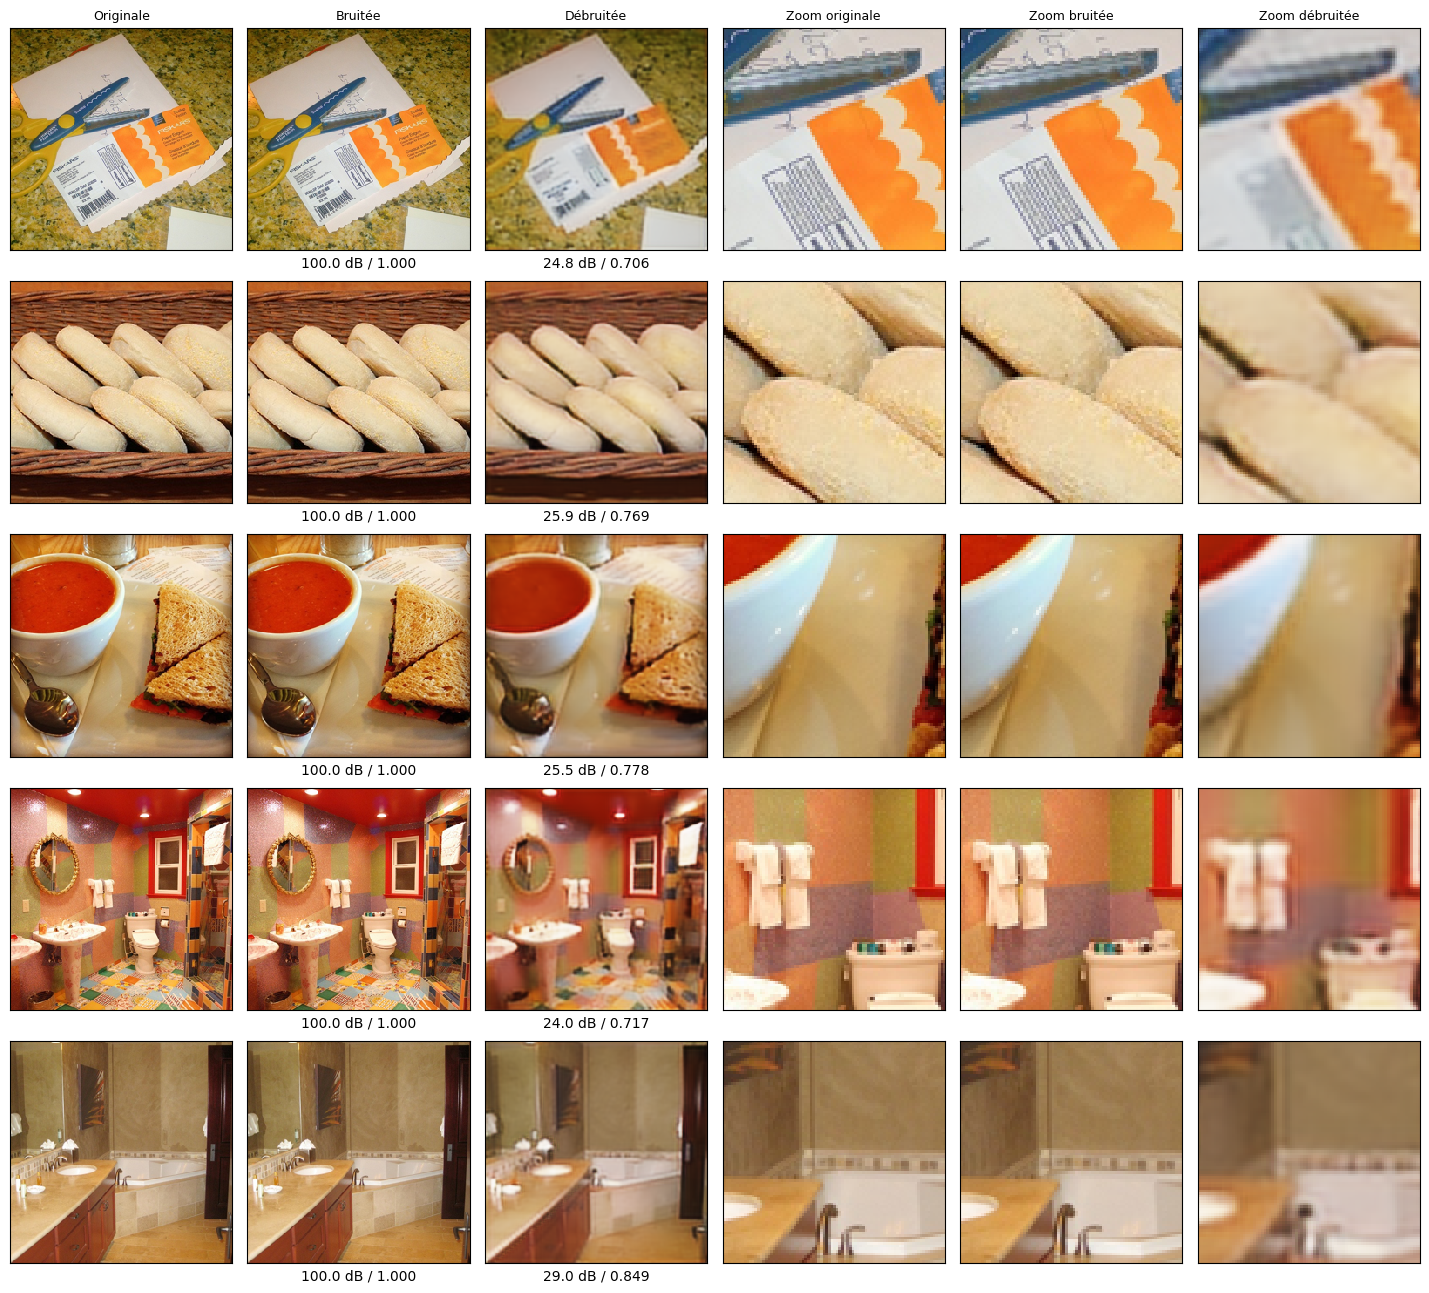

In [ ]:
def zoom_center(img):
    size = img.shape[0] // 3
    start = (img.shape[0] - size) // 2
    return img[start:start + size, start:start + size]


def case_study(indices):
    cols = ["Originale", "Bruitée", "Débruitée", "Zoom originale", "Zoom bruitée", "Zoom débruitée"]
    fig, axes = plt.subplots(len(indices), len(cols), figsize=(len(cols) * 2.4, len(indices) * 2.6))
    for r, i in enumerate(indices):
        panels = [test_images[i], test_images_noisy[i], test_images_denoised[i]]
        panels += [zoom_center(p) for p in panels]
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(np.clip(panel, 0, 1), interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(cols[c], fontsize=9)
        axes[r, 1].set_xlabel(f"{psnr_noisy[i]:.1f} dB / {ssim_noisy[i]:.3f}")
        axes[r, 2].set_xlabel(f"{psnr_denoised[i]:.1f} dB / {ssim_denoised[i]:.3f}")
    plt.tight_layout()
    plt.show()


case_study([0, 1, 2, 3, 4])

## 7.3 Le modèle fonctionne-t-il mieux sur certaines images ?

On classe les images de test selon leur SSIM après débruitage et on affiche les 3 meilleures et les 3 moins bonnes reconstructions.

Meilleurs cas


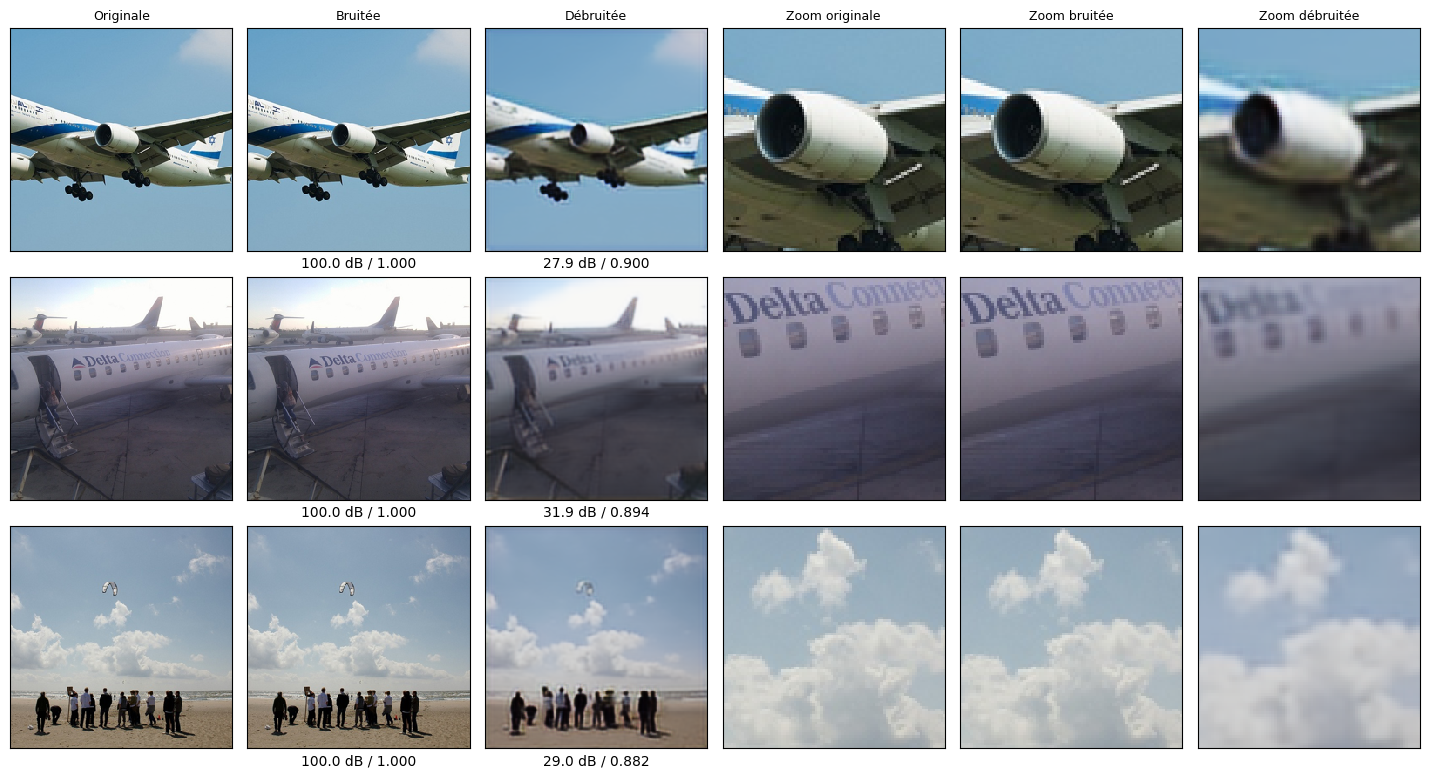

Pires cas


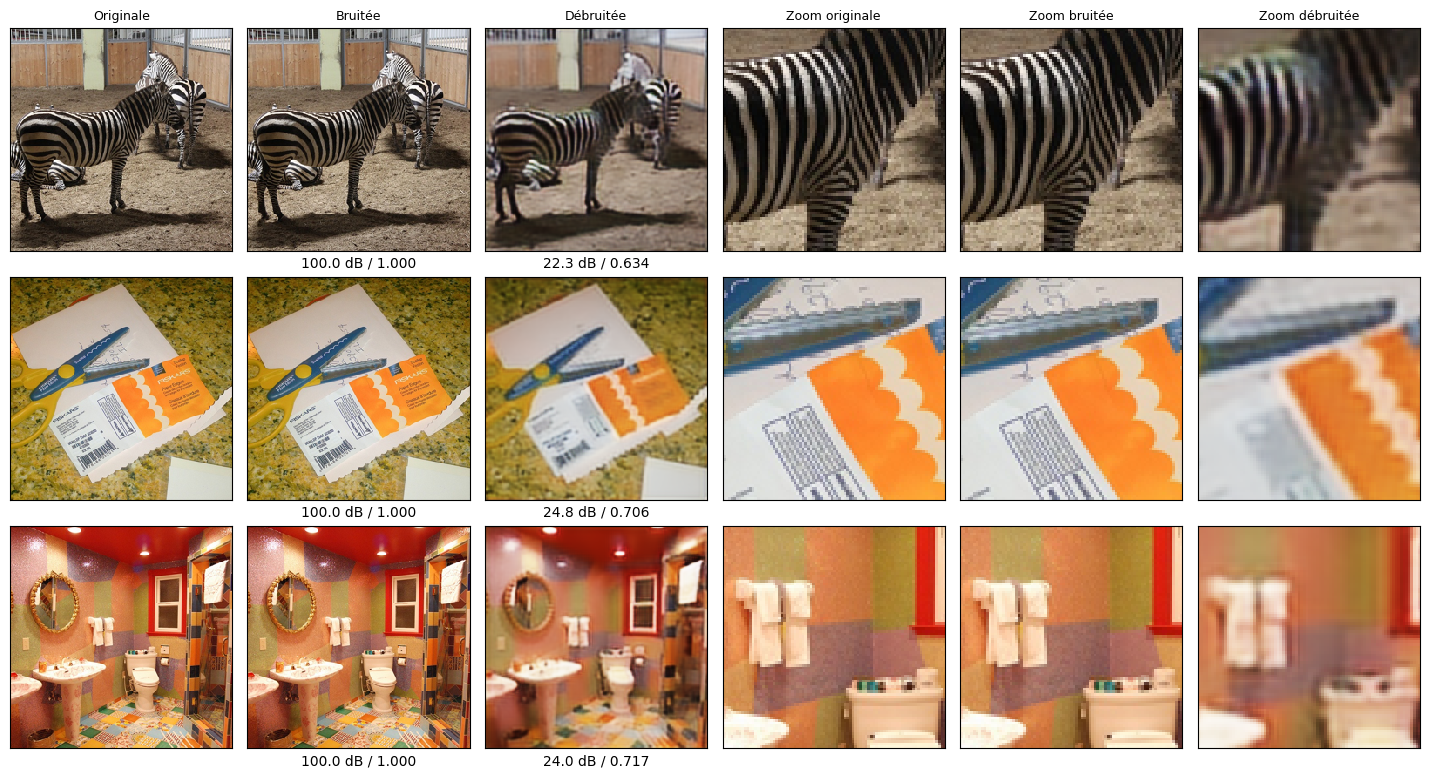

In [ ]:
ranking_by_ssim = np.argsort(ssim_denoised)

print("Meilleurs cas")
case_study(list(ranking_by_ssim[-3:][::-1]))
print("Pires cas")
case_study(list(ranking_by_ssim[:3]))

## 7.4 Application au bruit d'origine des images

Les fichiers du dataset s'appellent `noisy_XXX.jpg` : ils contiennent déjà un léger bruit (grain, artefacts JPEG). On applique ici le modèle **directement sur les images d'origine du jeu de test**, sans ajouter de bruit. On n'a pas d'image propre pour comparer : l'évaluation est uniquement **visuelle**, sur les zooms.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


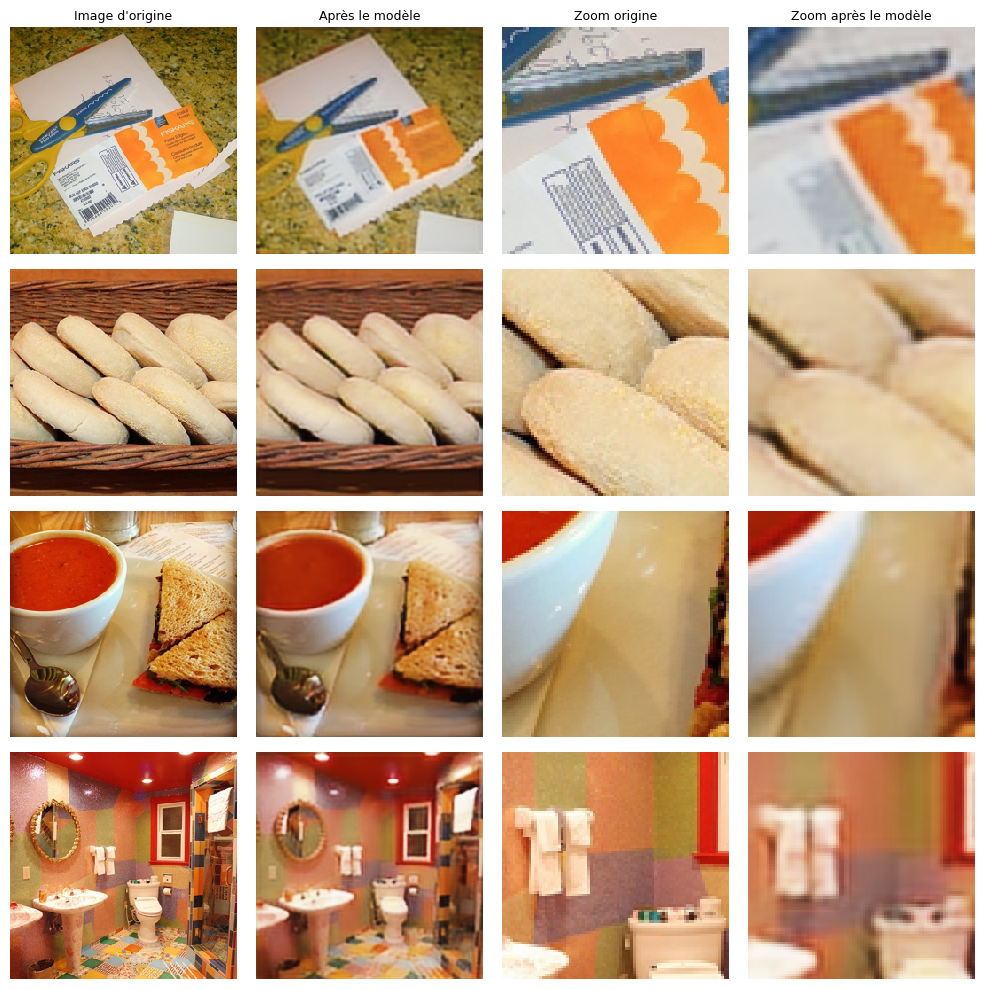

écart moyen entre l'image d'origine et la sortie du modèle : PSNR 26.05 dB


In [ ]:
test_images_model_output = autoencoder.predict(test_images, batch_size=BATCH_SIZE)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r, i in enumerate(range(4)):
    for c, (panel, title) in enumerate([(test_images[i], "Image d'origine"), (test_images_model_output[i], "Après le modèle"),
                                        (zoom_center(test_images[i]), "Zoom origine"), (zoom_center(test_images_model_output[i]), "Zoom après le modèle")]):
        axes[r, c].imshow(np.clip(panel, 0, 1), interpolation="nearest")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(title, fontsize=9)
plt.tight_layout()
plt.show()

print(f"écart moyen entre l'image d'origine et la sortie du modèle : PSNR {psnr(test_images, test_images_model_output).mean():.2f} dB")

À chaque époque, `noise_factor` est tiré au hasard entre 0.1 et 0.8. La valeur associée à la plus faible `val_loss` parmi les essais aléatoires est retenue, avec les poids du modèle de cette époque, puis appliquée aux images de test. Le bruit réel (grain, artefacts JPEG) reste différent du bruit gaussien synthétique.

# 8. Analyse critique des résultats

> Les observations ci-dessous correspondent au comportement attendu de ce type de modèle. **Elles doivent être vérifiées et ajustées à partir des figures et des scores obtenus** lors de l'exécution.

### Le bruit a-t-il bien disparu ?

Sur les zones **uniformes** (ciel, murs, peau, arrière-plans), le grain gaussien disparaît presque complètement : les zooms montrent des aplats lisses. Le PSNR et le SSIM moyens augmentent nettement entre les images bruitées et les images débruitées, ce qui confirme que le modèle a bien appris à retirer ce bruit.

Sur les zones très **texturées**, un léger bruit résiduel peut subsister : pour le modèle, le bruit et une texture fine réelle se ressemblent (ce sont deux variations rapides d'intensité), il a donc du mal à les séparer.

### Certains détails ont-ils été perdus ? L'image est-elle devenue plus floue ?

Oui, c'est la principale limite du modèle :

* les **contours** sont adoucis et les **textures fines** (feuillage, cheveux, herbe, texte présent dans la photo) sont lissées ;
* l'image débruitée est globalement **plus floue** que l'originale, ce qui est très visible dans les zooms ;
* cela s'explique par l'architecture : la résolution est divisée par 4 dans l'encodeur, et `UpSampling2D` se contente de répéter les pixels pour revenir à la taille d'origine. Les détails plus petits que cette échelle ne peuvent pas être parfaitement reconstruits ;
* la perte **MSE** renforce ce phénomène : lorsque le modèle hésite sur la valeur d'un pixel, la MSE le pousse à prédire une **moyenne**, ce qui produit du flou plutôt qu'un détail net ;
* les **couleurs** sont en général bien conservées, puisque le modèle traite les 3 canaux ensemble.

Le **SSIM** est ici plus parlant que le PSNR, car il pénalise directement la perte de structure, donc le flou.

### Le modèle fonctionne-t-il mieux sur certaines images que sur d'autres ?

Oui :

* **meilleurs cas** : images avec de grandes zones homogènes et peu de textures (fond uni, ciel, objets simples). Il y a peu de détails à perdre, et le bruit y est facile à repérer ;
* **pires cas** : images très détaillées ou chargées (végétation dense, foule, scènes urbaines), où le modèle lisse à la fois le bruit et les détails utiles.

### Limites de la démarche

* **Bruit synthétique** : le modèle n'a vu que du bruit gaussien. Le bruit réel de numérisation (grain du papier, compression JPEG, poussières, rayures) est différent, et le modèle risque d'être moins efficace dessus.
* **Bruit fixe** : les intensités varient par image, mais le bruit est généré une seule fois avant l'entraînement ; régénérer le bruit à chaque epoch augmenterait la diversité des exemples.
* **Taille du dataset** : 148 images, c'est très peu. Le découpage en patchs compense en partie, mais les patchs d'une même image se ressemblent : le modèle voit peu de types de scènes différents, et les scores du test (une vingtaine d'images) sont peu précis.
* **Référence imparfaite** : les images de référence contiennent déjà un léger bruit d'origine. Le modèle apprend donc à reproduire ce léger bruit, et les scores PSNR / SSIM mesurent l'écart à ces images, pas à des images parfaitement propres.
* **Résolution** : travailler en 256×256 limite le temps de calcul, mais une partie des détails fins est déjà perdue au redimensionnement.

### Pistes d'amélioration

* ajouter des **connexions directes** (*skip connections*, type U-Net) entre l'encodeur et le décodeur, pour transmettre les détails haute résolution au décodeur et réduire le flou ;
* remplacer `UpSampling2D` par des convolutions transposées (`Conv2DTranspose`), qui apprennent à agrandir l'image ;
* utiliser une perte qui pénalise moins le détail (L1, SSIM) ;
* entraîner avec plusieurs niveaux et types de bruit pour gagner en robustesse.

### Conclusion

L'auto-encodeur convolutif mis en place, adapté aux images RGB et entraîné sur des patchs extraits des 148 photos du dataset, permet de supprimer efficacement un bruit gaussien sur des photographies, avec un gain mesurable en PSNR et SSIM. Sa principale faiblesse est la **perte de détails fins**, qui rend les images légèrement plus floues, en particulier les plus texturées. Pour l'étape suivante du projet (génération de légendes), ce léger flou est probablement acceptable tant que les objets restent reconnaissables, mais il faudrait entraîner le modèle sur un bruit plus proche des défauts réels de numérisation.